# Notebook 2 — Klasifikasi Tweet Banjir: Naive Bayes vs KNN vs Decision Tree
**Proyek UTS Kecerdasan Artifisial: Agen Cerdas Tanggap Banjir Ciledug**

Tugas: memprediksi apakah sebuah tweet merupakan **laporan kejadian banjir nyata** (`laporan`) atau bukan (`bukan_laporan`).
Input: `data/processed/tweets_banjir.json` dari Notebook 1.

Alur:
1. Representasi fitur **TF-IDF** (unigram + bigram).
2. Tiga algoritma supervised learning: **Multinomial Naive Bayes**, **K-Nearest Neighbors**, **Decision Tree**.
3. Tuning hyperparameter dengan **GridSearchCV** 5-fold stratified, metrik optimasi **F1** (kelas tidak seimbang).
4. Evaluasi pada data uji: **Confusion Matrix, Akurasi, Presisi, Recall, F1**.
5. Analisis perbandingan dan pemilihan model terbaik.
6. Ekspor model terbaik ke JSON (dipakai web) dan simpan hasil ke Supabase.

In [1]:
import os, subprocess, sys
from pathlib import Path

if "google.colab" in sys.modules:
    if not Path("/content/repo").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/izviopm/uts-ai-banjir-ciledug.git", "/content/repo"], check=True)
    os.chdir("/content/repo")
elif Path("../data").exists():
    os.chdir("..")

In [2]:
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
FIG = Path("laporan/gambar"); FIG.mkdir(parents=True, exist_ok=True)
EXPORT = Path("web/public/model"); EXPORT.mkdir(parents=True, exist_ok=True)
SEED = 42

df = pd.read_json("data/processed/tweets_banjir.json")
train, test = df[df.split == "train"], df[df.split == "test"]
X_train, y_train = train.text_clean, (train.label == "laporan").astype(int)
X_test, y_test = test.text_clean, (test.label == "laporan").astype(int)
print(f"Latih: {len(train)}  Uji: {len(test)}  | proporsi laporan latih={y_train.mean():.3f} uji={y_test.mean():.3f}")

Latih: 976  Uji: 244  | proporsi laporan latih=0.301 uji=0.303


## 1. Representasi fitur: TF-IDF
$$\text{tfidf}(t,d) = \text{tf}(t,d) \times \log\frac{1+N}{1+\text{df}(t)} + 1$$
- `ngram_range=(1,2)`: bigram menangkap frasa seperti "rendam rumah" atau "tinggi air".
- `min_df=2`: buang kata yang hanya muncul di satu dokumen (noise/typo).
- `sublinear_tf=True`: frekuensi diskalakan logaritmik.

Vectorizer berada **di dalam Pipeline**, sehingga IDF hanya dihitung dari fold latih saat cross-validation (mencegah *data leakage*).

In [3]:
tfidf = dict(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
v = TfidfVectorizer(**tfidf).fit(X_train)
print("Ukuran kosakata:", len(v.vocabulary_))

Ukuran kosakata: 2851


## 2. Model dan ruang hyperparameter
| Model | Ide utama | Hyperparameter yang dicari |
|---|---|---|
| Multinomial Naive Bayes | Teorema Bayes dengan asumsi independensi antar kata: $P(c\mid d) \propto P(c)\prod_i P(w_i\mid c)$ | `alpha` (Laplace smoothing), `fit_prior` (pakai prior kelas atau seragam) |
| K-Nearest Neighbors | Kelas mayoritas dari *k* tetangga terdekat, jarak **cosine** (cocok untuk vektor teks) | `k`, `weights` |
| Decision Tree | Memecah data berdasar fitur yang memaksimalkan *information gain* / menurunkan impurity | `criterion`, `max_depth`, `min_samples_leaf` |

Semua model memakai F1 sebagai skor optimasi. Decision Tree diberi `class_weight="balanced"` untuk mengompensasi ketidakseimbangan kelas.
Untuk Naive Bayes, `fit_prior=False` (prior seragam) adalah padanannya; KNN tidak memiliki mekanisme ini.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
kandidat = {
    "naive_bayes": (MultinomialNB(), {"clf__alpha": [0.05, 0.1, 0.3, 0.5, 1.0], "clf__fit_prior": [True, False]}),
    "knn": (KNeighborsClassifier(metric="cosine"),
            {"clf__n_neighbors": [3, 5, 7, 11, 15, 21], "clf__weights": ["uniform", "distance"]}),
    "decision_tree": (DecisionTreeClassifier(random_state=SEED, class_weight="balanced"),
                      {"clf__criterion": ["gini", "entropy"], "clf__max_depth": [5, 10, 20, 40, None],
                       "clf__min_samples_leaf": [1, 2, 5]}),
}

hasil, terbaik = {}, {}
for nama, (clf, grid) in kandidat.items():
    pipe = Pipeline([("tfidf", TfidfVectorizer(**tfidf)), ("clf", clf)])
    gs = GridSearchCV(pipe, grid, scoring="f1", cv=cv, n_jobs=-1)
    t0 = time.perf_counter(); gs.fit(X_train, y_train); waktu = (time.perf_counter() - t0) * 1000
    best = gs.best_estimator_
    cvs = cross_val_score(best, X_train, y_train, scoring="f1", cv=cv)
    y_pred = best.predict(X_test)
    proba = best.predict_proba(X_test)[:, 1]
    terbaik[nama] = best
    hasil[nama] = dict(
        accuracy=float(accuracy_score(y_test, y_pred)), precision_score=float(precision_score(y_test, y_pred)),
        recall=float(recall_score(y_test, y_pred)), f1=float(f1_score(y_test, y_pred)),
        cv_f1_mean=float(cvs.mean()), cv_f1_std=float(cvs.std()),  # float(): psycopg2 tidak mengenali np.float64
        confusion_matrix=confusion_matrix(y_test, y_pred).tolist(),
        best_params={k.replace("clf__", ""): v for k, v in gs.best_params_.items()},
        train_time_ms=waktu, y_pred=y_pred, proba=proba,
    )
    print(f"{nama:14s} best={hasil[nama]['best_params']}  CV-F1={cvs.mean():.3f}±{cvs.std():.3f}  test-F1={hasil[nama]['f1']:.3f}")

naive_bayes    best={'alpha': 0.1, 'fit_prior': False}  CV-F1=0.687±0.025  test-F1=0.612


knn            best={'n_neighbors': 7, 'weights': 'distance'}  CV-F1=0.585±0.044  test-F1=0.565


decision_tree  best={'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 1}  CV-F1=0.518±0.058  test-F1=0.518


## 3. Evaluasi pada data uji

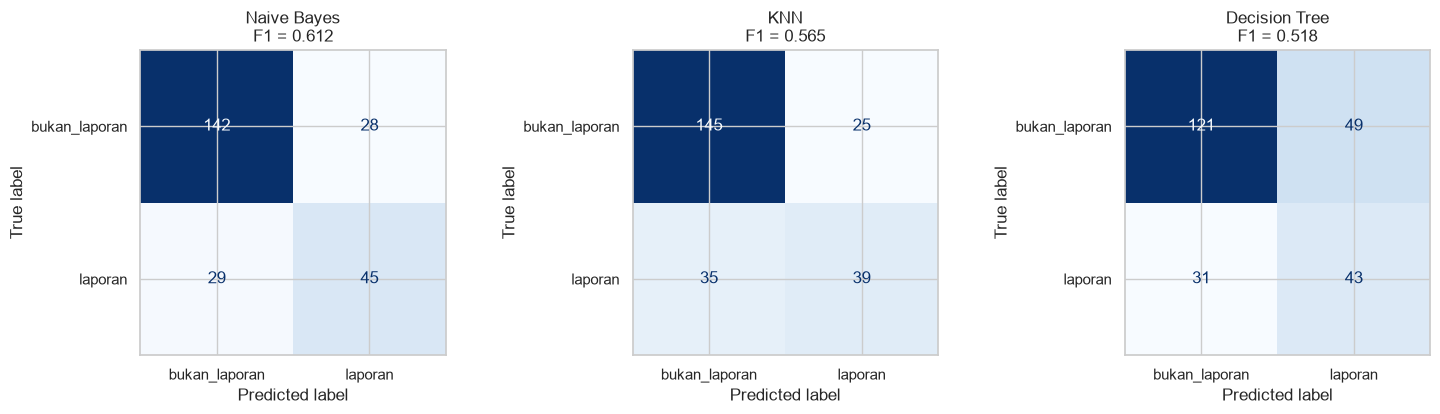

In [5]:
NAMA = {"naive_bayes": "Naive Bayes", "knn": "KNN", "decision_tree": "Decision Tree"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (nama, h) in zip(axes, hasil.items()):
    ConfusionMatrixDisplay(np.array(h["confusion_matrix"]), display_labels=["bukan_laporan", "laporan"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{NAMA[nama]}\nF1 = {h['f1']:.3f}")
plt.tight_layout(); plt.savefig(FIG / "02_confusion_matrix.png", dpi=150); plt.show()

In [6]:
for nama, h in hasil.items():
    print(f"===== {NAMA[nama]} =====")
    print(classification_report(y_test, h["y_pred"], target_names=["bukan_laporan", "laporan"], digits=3))

===== Naive Bayes =====
               precision    recall  f1-score   support

bukan_laporan      0.830     0.835     0.833       170
      laporan      0.616     0.608     0.612        74

     accuracy                          0.766       244
    macro avg      0.723     0.722     0.723       244
 weighted avg      0.766     0.766     0.766       244

===== KNN =====
               precision    recall  f1-score   support

bukan_laporan      0.806     0.853     0.829       170
      laporan      0.609     0.527     0.565        74

     accuracy                          0.754       244
    macro avg      0.707     0.690     0.697       244
 weighted avg      0.746     0.754     0.749       244

===== Decision Tree =====
               precision    recall  f1-score   support

bukan_laporan      0.796     0.712     0.752       170
      laporan      0.467     0.581     0.518        74

     accuracy                          0.672       244
    macro avg      0.632     0.646     0.635  

In [7]:
metrik = ["accuracy", "precision_score", "recall", "f1", "cv_f1_mean"]
tabel = pd.DataFrame({NAMA[n]: {m: h[m] for m in metrik + ["cv_f1_std", "train_time_ms"]} for n, h in hasil.items()}).T
tabel.columns = ["Akurasi", "Presisi", "Recall", "F1 (uji)", "F1 (CV mean)", "F1 (CV std)", "Waktu tuning (ms)"]
tabel.round(3)

,Akurasi,Presisi,Recall,F1 (uji),F1 (CV mean),F1 (CV std),Waktu tuning (ms)
Naive Bayes,0.766,0.616,0.608,0.612,0.687,0.025,20654.881
KNN,0.754,0.609,0.527,0.565,0.585,0.044,1398.581
Decision Tree,0.672,0.467,0.581,0.518,0.518,0.058,1885.924


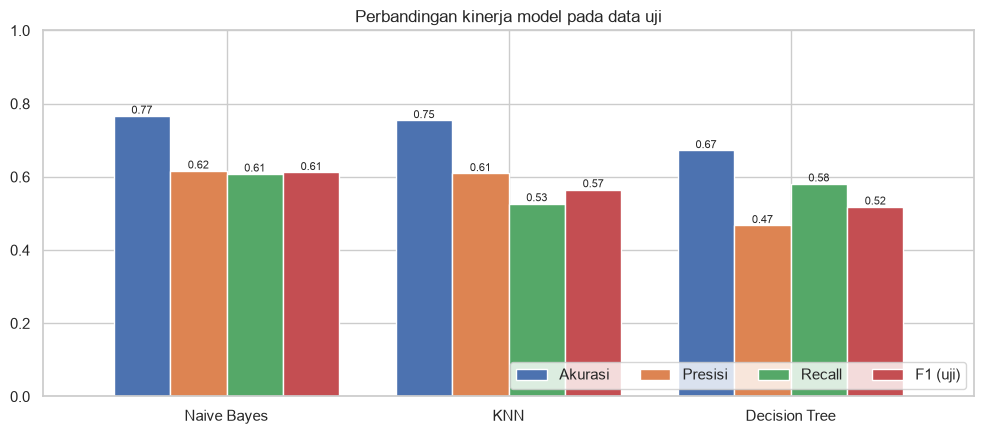

In [8]:
ax = tabel[["Akurasi", "Presisi", "Recall", "F1 (uji)"]].plot.bar(figsize=(10, 4.5), rot=0, width=0.8)
ax.set_ylim(0, 1); ax.set_title("Perbandingan kinerja model pada data uji"); ax.legend(loc="lower right", ncol=4)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "02_perbandingan_metrik.png", dpi=150); plt.show()

## 4. Decision Tree sebagai proses *searching*
Pembentukan Decision Tree adalah **pencarian greedy** di ruang kemungkinan pohon (dibahas di BAB II laporan):
- **State**: sebuah node berisi subset data latih.
- **Action**: memilih satu fitur (kata/bigram) dan ambang batas untuk memecah node.
- **Heuristik**: pilih aksi dengan *information gain* terbesar (penurunan entropy/Gini terbesar).
- **Goal test**: node murni, atau batas `max_depth` / `min_samples_leaf` tercapai.

Visualisasi 3 level teratas pohon terbaik:

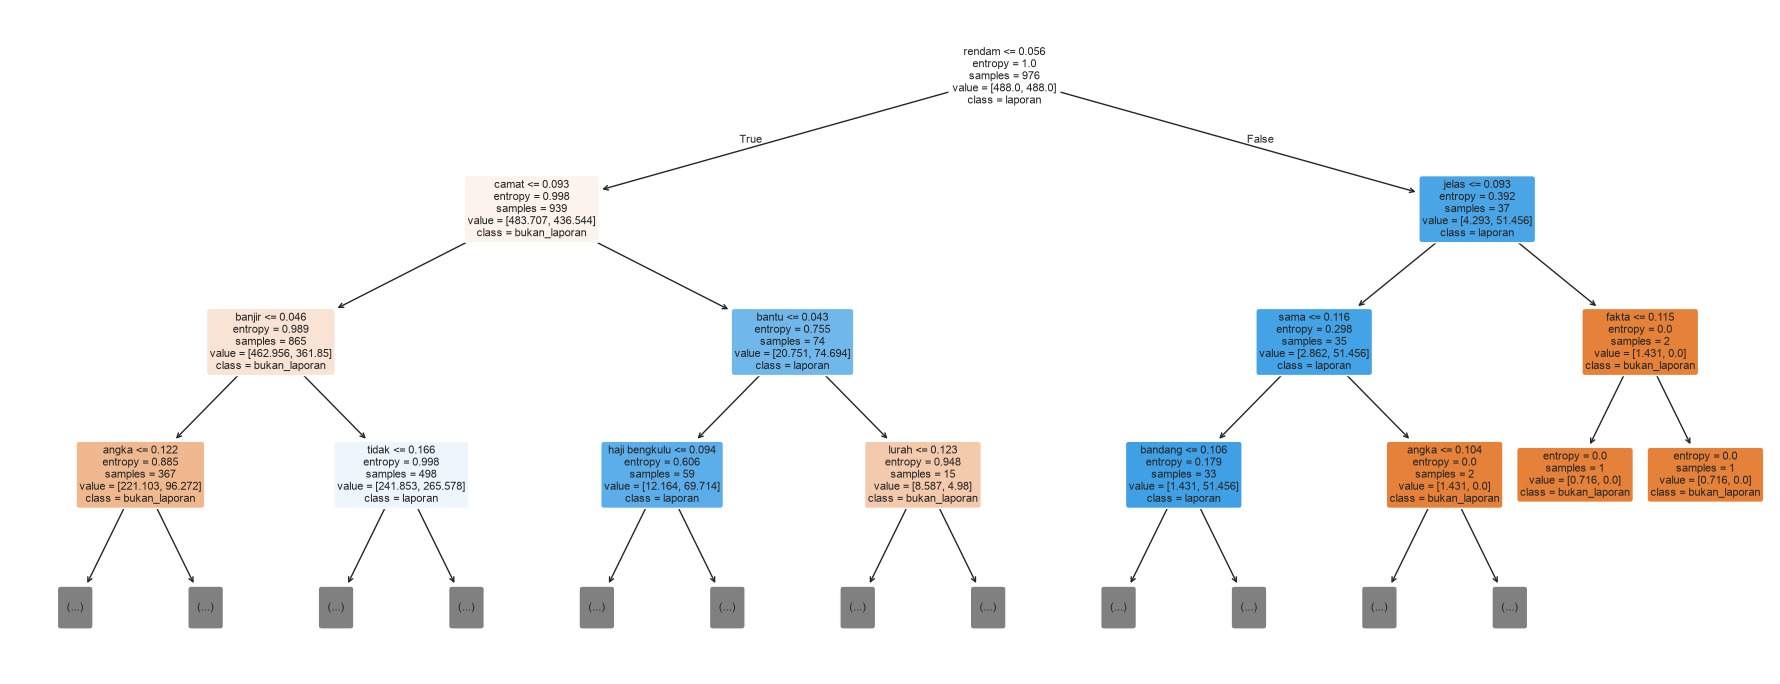

,importance
banjir,0.1062
angka,0.0601
rendam,0.0365
camat,0.0350
bantu,0.0322
titik,0.0183
tidak,0.0177
angka angka,0.0165
dalam,0.0159
bandang,0.0159


In [9]:
dt = terbaik["decision_tree"]
fitur = dt.named_steps["tfidf"].get_feature_names_out()
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(dt.named_steps["clf"], max_depth=3, feature_names=fitur, class_names=["bukan_laporan", "laporan"],
          filled=True, rounded=True, fontsize=8, impurity=True, proportion=False, ax=ax)
plt.tight_layout(); plt.savefig(FIG / "02_decision_tree.png", dpi=150); plt.show()

imp = pd.Series(dt.named_steps["clf"].feature_importances_, index=fitur).nlargest(15)
imp.round(4).to_frame("importance")

## 5. Interpretasi Naive Bayes: kata paling diskriminatif
Rasio log-probabilitas $\log P(w\mid \text{laporan}) - \log P(w\mid \text{bukan\_laporan})$ menunjukkan kata yang paling mendorong prediksi ke tiap kelas.

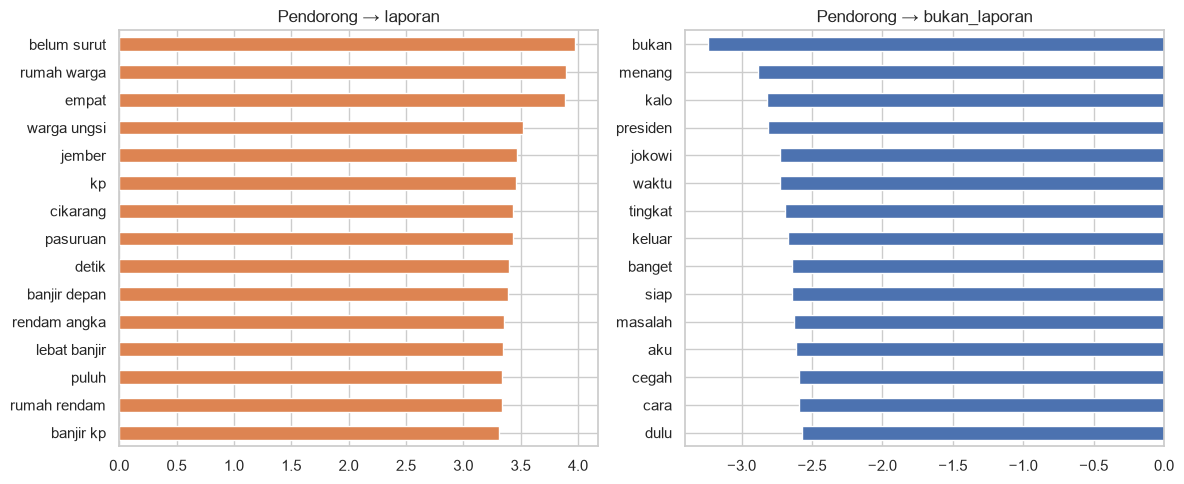

In [10]:
nb = terbaik["naive_bayes"]
fnb = nb.named_steps["tfidf"].get_feature_names_out()
lp = nb.named_steps["clf"].feature_log_prob_
rasio = pd.Series(lp[1] - lp[0], index=fnb)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
rasio.nlargest(15)[::-1].plot.barh(ax=ax[0], color="#DD8452", title="Pendorong → laporan")
rasio.nsmallest(15)[::-1].plot.barh(ax=ax[1], color="#4C72B0", title="Pendorong → bukan_laporan")
plt.tight_layout(); plt.savefig(FIG / "02_nb_kata_diskriminatif.png", dpi=150); plt.show()

## 6. Contoh kesalahan prediksi (error analysis)

In [11]:
# Model dipilih dari skor cross-validation (data latih), BUKAN dari data uji, agar evaluasi uji tetap jujur
terbaik_nama = max(hasil, key=lambda n: hasil[n]["cv_f1_mean"])
salah = test.assign(pred=np.where(hasil[terbaik_nama]["y_pred"] == 1, "laporan", "bukan_laporan"))
salah = salah[salah.pred != salah.label][["text_raw", "label", "pred"]]
print(f"Model terbaik: {NAMA[terbaik_nama]} — {len(salah)} kesalahan dari {len(test)} data uji")
pd.set_option("display.max_colwidth", 140)
salah.head(10)

Model terbaik: Naive Bayes — 57 kesalahan dari 244 data uji


,text_raw,label,pred
5,keadaan banjir di seberang jaya jam 6:45pg tadi,bukan_laporan,laporan
20,konsumsi siap di bungkus untuk kemudian akan segera di distribusikan ke masyarakat terdampak banjir di wilayah kecamatan pesanggaran,laporan,bukan_laporan
36,sisi lain penyuluh pertanian dalam pemantauan banjir pada persawahan di kota pekalongan,laporan,bukan_laporan
57,banjir sekitar 25 cuma di jalan palang merah medan mohon berhati hati cc :,laporan,bukan_laporan
62,polsek panimbang bersama muspika laksanakan pengobatan gratis kepada warga yang terdampak banjir musiman di pustu kp keusik,bukan_laporan,laporan
102,mendengar curahan hati warga yang terkena musibah banjir di daerah bale kambang condet jakarta timur,laporan,bukan_laporan
125,luhkan kecamatan gabus mendata kolam air tawar yang terkena banjir di desa wuwur kecamatan gabus kolam yang terkena banjir 65 ha dengan ...,laporan,bukan_laporan
145,relawan ldii kabupaten demak minggu 18 pebruari 2018 bergabung dengan relawan yang lain di dalam menyediakan nasi bungkus untuk korban b...,laporan,bukan_laporan
147,pramuka peduli salurkan donasi bantuan untuk korban banjir di posko induk sidakaton dukuhturi jum'at ( 16/2 ) berbagi itu indah semoga m...,laporan,bukan_laporan
172,banser langsung turun membantu korban banjir di gresik,bukan_laporan,laporan


## 7. Kesimpulan perbandingan
Model dipilih berdasarkan **F1 cross-validation** pada data latih; data uji hanya dipakai sekali untuk melaporkan kinerja akhir.
Kesimpulan dicetak otomatis dari angka di atas, sehingga selalu konsisten dengan hasil eksekusi.

In [12]:
urut = sorted(hasil, key=lambda n: hasil[n]["f1"], reverse=True)
for i, n in enumerate(urut, 1):
    h = hasil[n]
    print(f"{i}. {NAMA[n]:13s} F1={h['f1']:.3f}  Akurasi={h['accuracy']:.3f}  Presisi={h['precision_score']:.3f}  "
          f"Recall={h['recall']:.3f}  CV-F1={h['cv_f1_mean']:.3f}±{h['cv_f1_std']:.3f}")
print(f"\nModel terpilih (F1 cross-validation tertinggi): {NAMA[terbaik_nama]}")
print(f"Model dengan F1 uji tertinggi: {NAMA[urut[0]]}")
if terbaik_nama != urut[0]:
    print("Catatan: urutan CV dan uji berbeda. Data uji kecil (74 laporan), jadi skor uji lebih berfluktuasi; "
          "keputusan tetap mengikuti CV yang dirata-rata dari 5 fold.")

1. Naive Bayes   F1=0.612  Akurasi=0.766  Presisi=0.616  Recall=0.608  CV-F1=0.687±0.025
2. KNN           F1=0.565  Akurasi=0.754  Presisi=0.609  Recall=0.527  CV-F1=0.585±0.044
3. Decision Tree F1=0.518  Akurasi=0.672  Presisi=0.467  Recall=0.581  CV-F1=0.518±0.058

Model terpilih (F1 cross-validation tertinggi): Naive Bayes
Model dengan F1 uji tertinggi: Naive Bayes


## 8. Ekspor model untuk web (inferensi di browser)
Model Naive Bayes diekspor sebagai JSON: kosakata, nilai IDF, log prior, dan log likelihood tiap kata.
Web Next.js menghitung TF-IDF → skor NB dengan rumus yang sama tanpa server Python.
Preprocessing (stopword, slang) ikut diekspor. Stemming di web memakai port Sastrawi untuk JavaScript.

In [13]:
v_nb, c_nb = nb.named_steps["tfidf"], nb.named_steps["clf"]
vocab = v_nb.get_feature_names_out().tolist()
model_json = {
    "model": "MultinomialNB", "classes": ["bukan_laporan", "laporan"],
    "tfidf": {"ngram_range": [1, 2], "sublinear_tf": True, "norm": "l2"},
    "vocab": vocab, "idf": np.round(v_nb.idf_, 6).tolist(),
    "class_log_prior": c_nb.class_log_prior_.tolist(),
    "feature_log_prob": np.round(c_nb.feature_log_prob_, 6).tolist(),
    "metrics": {k: round(hasil["naive_bayes"][k], 4) for k in ["accuracy", "precision_score", "recall", "f1"]},
}
(EXPORT / "naive_bayes.json").write_text(json.dumps(model_json, separators=(",", ":")))
print("Ukuran:", round((EXPORT / "naive_bayes.json").stat().st_size / 1024), "KB")

# Uji konsistensi: implementasi manual (seperti di web) harus sama dengan sklearn
def prediksi_manual(teks):
    idx = {w: i for i, w in enumerate(vocab)}
    tok = teks.split(); grams = tok + [" ".join(p) for p in zip(tok, tok[1:])]
    tf = {}
    for g in grams:
        if g in idx: tf[idx[g]] = tf.get(idx[g], 0) + 1
    vec = {i: (1 + np.log(c)) * v_nb.idf_[i] for i, c in tf.items()}
    norm = np.sqrt(sum(x * x for x in vec.values())) or 1
    skor = [c_nb.class_log_prior_[k] + sum(x / norm * c_nb.feature_log_prob_[k][i] for i, x in vec.items()) for k in (0, 1)]
    return int(np.argmax(skor))

manual = np.array([prediksi_manual(t) for t in X_test])
assert (manual == nb.predict(X_test)).all(), "Implementasi manual tidak sama dengan sklearn"
print("✓ Prediksi manual identik dengan sklearn pada", len(X_test), "data uji")

Ukuran: 112 KB
✓ Prediksi manual identik dengan sklearn pada 244 data uji


## 9. Simpan hasil ke Supabase
Membutuhkan secret `SUPABASE_DB_URL` (Session pooler URI). Di Colab: ikon 🔑 → Add secret. Jika tidak ada, langkah ini dilewati.

In [14]:
db_url = os.environ.get("SUPABASE_DB_URL")
if "google.colab" in sys.modules and not db_url:
    try:
        from google.colab import userdata
        db_url = userdata.get("SUPABASE_DB_URL")
    except Exception:
        db_url = None

if not db_url:
    print("SUPABASE_DB_URL tidak ditemukan — penyimpanan ke Supabase dilewati.")
else:
    import psycopg2
    from psycopg2.extras import execute_values, Json
    with psycopg2.connect(db_url) as conn, conn.cursor() as cur:
        execute_values(cur, """insert into uts_ai_bencana.tweets (id, text_raw, text_clean, label, split, locations)
            values %s on conflict (id) do update set text_clean = excluded.text_clean, label = excluded.label,
            split = excluded.split, locations = excluded.locations""",
            [(r.id, r.text_raw, r.text_clean, r.label, r.split, list(r.locations)) for r in df.itertuples()])
        rows = [(tid, n, "laporan" if p else "bukan_laporan", float(pr))
                for n, h in hasil.items() for tid, p, pr in zip(test.id, h["y_pred"], h["proba"])]
        execute_values(cur, """insert into uts_ai_bencana.predictions (tweet_id, model, predicted, probability) values %s
            on conflict (tweet_id, model) do update set predicted = excluded.predicted, probability = excluded.probability""", rows)
        for n, h in hasil.items():
            cur.execute("""insert into uts_ai_bencana.model_metrics (model, accuracy, precision_score, recall, f1, cv_f1_mean,
                cv_f1_std, confusion_matrix, best_params, train_time_ms) values (%s,%s,%s,%s,%s,%s,%s,%s,%s,%s)
                on conflict (model) do update set accuracy=excluded.accuracy, precision_score=excluded.precision_score,
                recall=excluded.recall, f1=excluded.f1, cv_f1_mean=excluded.cv_f1_mean, cv_f1_std=excluded.cv_f1_std,
                confusion_matrix=excluded.confusion_matrix, best_params=excluded.best_params,
                train_time_ms=excluded.train_time_ms, created_at=now()""",
                (n, h["accuracy"], h["precision_score"], h["recall"], h["f1"], h["cv_f1_mean"], h["cv_f1_std"],
                 Json(h["confusion_matrix"]), Json(h["best_params"]), h["train_time_ms"]))
    print(f"✓ Tersimpan: {len(df)} tweet, {len(rows)} prediksi, {len(hasil)} metrik model")

SUPABASE_DB_URL tidak ditemukan — penyimpanan ke Supabase dilewati.


In [15]:
# Simpan juga ke file supaya bisa dibaca tanpa database
ringkas = {n: {k: v for k, v in h.items() if k not in ("y_pred", "proba")} for n, h in hasil.items()}
Path("data/processed/model_metrics.json").write_text(json.dumps(ringkas, indent=1, default=float))

1260